# Gaussian vs generalised Gaussian tuning-curve fits (BZ15)

This notebook fits two models to each cell's tuning curve. It trains on the mean of the even repeats and tests on the mean of the odd repeats. It uses symbfitrs for optimization and retains the original PyTorch models for prediction.

Saved outputs may predate the solver change. Run all cells to regenerate them; the new exports use `_will_` filenames to keep the original notebook's outputs intact. The current fit does not need Rust/Cargo.

* **Gaussian:** $f(\theta) = b + A_1 g(\theta-\phi) + A_2 g(\theta-\phi-\pi)$, with $g(u) = e^{-\frac12 (u/\sigma)^2}$.
* **Generalised Gaussian (BZ15 model):** $f(\theta) = b + A_1 g_1(\theta-\phi) + A_2 g_2(\theta-\phi-\pi)$, with $g_j(u) = e^{-\frac12 (|u|/\sigma_{j\pm})^{p_j}}$. The second peak is fixed opposite the first. Each peak has its own amplitude, separate widths either side of the peak, and its own exponent $p_j$. $p = 2$ is Gaussian; $p < 2$ is peakier.

Both fitting and scoring use the circular distance to each peak.
Each fit starts from the existing parameter estimator and is refined on CPU with symbfitrs. Both models add a penalty for moving away from that start (see **Fit**), so this is not an optimizer-only comparison with the Adam notebook. Test R² still uses the odd repeats, which are held out from the even-repeat fits.

In [20]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'   # torch and matplotlib load separate OpenMP runtimes; without this the kernel aborts when plotting. Must be set before importing torch.

import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.stats import wilcoxon

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print(f"Using device: {DEVICE}")

Using device: mps


## Load data

Bin the 3 blocks of 1024 sorted trials into `R_binned`, shape `(n_repeats, n_cells, n_bins)`, and `angles`, shape `(n_bins,)`, in radians.

Each of the 256 bins holds 12 trials. Trials are ordered by angle, then block, and each pseudo-repeat takes every 6th trial in the bin, so the 2 trials in a pseudo-repeat come from the same block.

In [21]:
N_BINS, N_REPEATS = 256, 6

data = np.load("JR026/collated_exp04-01.npz")
R_binned, angles = data["R_binned"], np.deg2rad(data["orientation"])   # the collated file stores directions in degrees
cell_names = data["cell_names"]                            # (n_cells,) e.g. JR026_2026-04-01_156; fixed to the cell's original position, whatever gets filtered out below
plane = data["plane"]                                      # (n_cells,) suite2p plane of every cell

angles[angles >= 6.2831] = 2 * np.pi - 1e-5               # 0 and 2π are the same angle
n_repeats, n_cells_all, n_trials = R_binned.shape
assert len(cell_names) == len(plane) == n_cells_all, "cell_names / plane and R_binned disagree: re-run the save cell in jacob_data_explorer.ipynb"

trials = R_binned.transpose(1, 0, 2).reshape(n_cells_all, -1)   # (n_cells, 512): repeat 1's trials, then repeat 2's
trial_angles = np.tile(angles, n_repeats)                       # (512,)

print(R_binned.shape)

(2, 53826, 256)


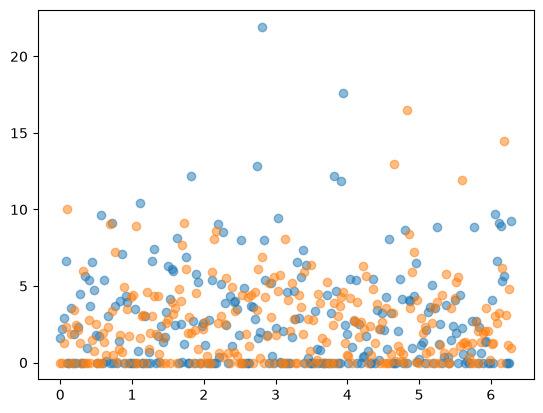

In [22]:
# plot a random cell
cell_no = np.random.randint(1000)
plt.scatter(angles, R_binned[0,cell_no], alpha=0.5)
plt.scatter(angles, R_binned[1, cell_no], alpha=0.5)
plt.show()

## Select cells

The next cells keep the cells to fit, using two criteria. Here $\mu_s$ is a cell's mean response in angle bin $s$ ($N$ bins), $\sigma_s^2$ is the variance across repeats in that bin, and $K$ is the number of repeats.

**Reliability**, also called signal fraction (Sahani & Linden 2003 [but actually, see Kenneth Harris' lecture on rate coding in NEUR0019]). It is the fraction of the variance of the trial-averaged curve that comes from the stimulus. We keep cells with SF > 0.6:
$$S^2 = \tfrac1N\textstyle\sum_s(\mu_s-\bar\mu)^2 - \tfrac{N-1}{N^2}\sum_s \sigma_s^2/K, \qquad V^2 = \tfrac1N\sum_s \sigma_s^2/K, \qquad \mathrm{SF} = \frac{S^2}{S^2+V^2}.$$
For my sanity: a cell is kept if its signal variance makes up a large proportion of the total response variance (which is a sum of the signal variance and the variance associated with noise, i.e. trial-trial variance). This implies a couple things. First of all, it is important to remember that if a cell's responses are totally but reliably flat, the $SF$ will still approach 0, because its responses do not vary with signal and thus $S^2$ is close to 0. Second – and I kind of already said this, but it bears repeating – this means that this selection measure is not just for reliability of signal, but rather reliable signal that varies with our stimulus condition (orientation tuning). The concentration selection criterion also does this, but in a different way.

Also from the conversation with Reilly: the first part of the equation for $S^2$ is just the variance of the trial-averaged responses across all stimulus conditions, which intuitively should account for all of signal variance ($S^2$). However, apparently, this overestimates signal variance because there is noise variance. That is what the second term is for ($\tfrac{N-1}{N^2}\sum_s \sigma_s^2/K$), which we can kind of intuitively see shrinks when we increase our number of repeats ($K$). The derivation for this is apparently complicated, and I am going on faith that Reilly worked it out correctly.

**Concentration.** It is 0 for a flat curve and 1 for a single spike. It uses $m=2$, for two peaks $180°$ apart, and is computed on the individual trials $t$. We keep cells with $C > 0.3$:
$$C_m = \frac{|\sum_t r_t e^{im\theta_t}|}{\sum_t r_t}.$$

Responses should be non-negative, because the models' baselines and amplitudes cannot go below zero.

### Signal fraction metric:

In [23]:
def unbiased_signal_fraction(R):
    """R: (n_repeats, n_cells, n_angles)"""
    n_repeats, n_cells, n_c = R.shape
    mu    = np.nanmean(R, axis=0)
    var_c = np.nanvar(R, axis=0, ddof=1)
    N     = n_c
    R_s   = np.nansum(~np.isnan(R), axis=0).mean(axis=0).clip(min=1)
    fbar  = np.nanmean(mu, axis=1)
    S2 = np.nanmean((mu - fbar[:, None])**2, axis=1) - ((N-1)/N**2) * np.sum(var_c / R_s, axis=1)
    V2 = np.sum(var_c / R_s, axis=1) / N
    return np.clip(S2 / (S2 + V2 + 1e-12), 0, 1)

### Normalise each repeat to RMS 1

The scale matters: Adam's step size is absolute, so it sets how fast amplitudes move relative to their size.

In [24]:
def normalise_reps(R):
    """R: (n_repeats, n_cells, n_angles). Each (repeat, cell) ends up with RMS 1 across angles."""
    rms = np.linalg.norm(R, axis=-1, keepdims=True) / np.sqrt(R.shape[-1])
    return R / rms

### Concentration

In [25]:
def circular_osi(mean_tc, angles_rad):
    """mean_tc: (n_cells, n_angles_rad), angles_rad: (n_angles_rad,). Also works on raw trials."""
    r_clip = np.clip(mean_tc, 0, None)
    denom  = r_clip.sum(axis=1)
    return np.where(denom > 0, np.abs((r_clip * np.exp(2j * angles_rad)).sum(axis=1)) / denom, 0.0)

### Keep only the cells that meet both thresholds (and are not in an excluded plane), and normalise them

Cells in `EXCLUDED_PLANES` (plane 0 by default, which spans the whole depth range) are skipped here. They stay in `cell_names` and in the screened-cells file, as `False`.

In [26]:
SF_THRESH, C_THRESH = 0.6, 0.3
EXCLUDED_PLANES = (0,)   # !!! cells in these planes are skipped by everything below (they stay in cell_names and the screened-cells file as False). Use () to keep every plane

# 1. concentration on the raw trials; drop silent cells, cells with an all-zero repeat, and cells in excluded planes
C = circular_osi(trials, trial_angles)
active = (trials > 0).any(axis=1)
has_signal = (np.linalg.norm(R_binned, axis=-1) > 0).all(axis=0)
plane_ok = ~np.isin(plane, EXCLUDED_PLANES)
print(f"{(~plane_ok).sum()} of {n_cells_all} cells are in excluded planes {EXCLUDED_PLANES} and skipped")
first_mask = active & has_signal & plane_ok & (C > C_THRESH)   # original indexes that survive the first filter
R_binned = R_binned[:, first_mask]
print(f"{R_binned.shape[1]} of {n_cells_all} cells have C > {C_THRESH}")

# 2. normalise each repeat
R_binned = normalise_reps(R_binned)

# 3. signal fraction on the normalised repeats
sf = unbiased_signal_fraction(R_binned)
keep = np.isfinite(sf) & (sf > SF_THRESH)
print(f"kept {keep.sum()} cells (SF > {SF_THRESH}, C > {C_THRESH})")
R_binned = R_binned[:, keep]

3505 of 53826 cells are in excluded planes (0,) and skipped
15595 of 53826 cells have C > 0.3
kept 3077 cells (SF > 0.6, C > 0.3)


In [27]:
print(f"{keep.sum()} of {n_cells_all} cells pass unbiased_signal_fraction (SF > {SF_THRESH})")
first_pass = np.where(first_mask)[0]                            # original indexes that survived the first filter (including the plane exclusion)
sf_pass_idx = first_pass[keep]                                  # original indexes that also pass SF > SF_THRESH
print(len(sf_pass_idx), sf_pass_idx)
assert not np.isin(plane[sf_pass_idx], EXCLUDED_PLANES).any()

survivor_names = cell_names[sf_pass_idx]                        # survivor k (row k of R_binned, R_train, params, r2) is survivor_names[k]
assert len(survivor_names) == R_binned.shape[1], "names and surviving cells are out of step: re-run from the load cell"
print(survivor_names[:5])

3077 of 53826 cells pass unbiased_signal_fraction (SF > 0.6)
3077 [ 3539  3607  3628 ... 53720 53726 53773]
['JR026_2026-04-01_3539' 'JR026_2026-04-01_3607' 'JR026_2026-04-01_3628'
 'JR026_2026-04-01_3638' 'JR026_2026-04-01_3643']


In [28]:
stem = cell_names[0].rsplit("_", 1)[0]                         # mouse_date, e.g. JR026_2026-04-01
passed_screens = np.zeros(n_cells_all, dtype=bool)              # same order as cell_names: passed_screens[i] belongs to cell_names[i]
passed_screens[sf_pass_idx] = True

screened_path = f"JR026/{stem}_will_screenedcells.npz"
np.savez(screened_path, cell_names=cell_names, passed_screens=passed_screens,
         screen_sf_thresh=SF_THRESH, screen_c_thresh=C_THRESH,                  # the thresholds this screen used (SF > and C >)
         screen_excluded_planes=np.array(EXCLUDED_PLANES, dtype=int))           # the planes skipped (empty = every plane kept)
print(f"saved {screened_path}: {passed_screens.sum()} of {n_cells_all} cells pass the screens")

saved JR026/JR026_2026-04-01_will_screenedcells.npz: 3077 of 53826 cells pass the screens


## Models and parameter estimators

In [29]:
MIN_WIDTH, MAX_WIDTH, P_MIN, P_MAX = 0.1, 2 * np.pi, 0.1, 4.0   # generalised Gaussian clips


def peak(theta, mu, w_left, w_right, p=None):
    # one peak per cell, (n_cells, n_bins), on the circular distance. p=None: Gaussian.
    d = theta[None, :] - mu[:, None]
    d = torch.atan2(torch.sin(d), torch.cos(d))
    u = d.abs().clamp(min=1e-12) / torch.where(d < 0, w_left[:, None], w_right[:, None])
    return torch.exp(-0.5 * (u * u if p is None else u ** p[:, None]))


def gauss(theta, P):
    # P: [theta_pref, baseline, amplitude_1, amplitude_2, width]
    t, b, a1, a2, w = P.unbind(-1)
    t, w = t.clamp(0, 2 * np.pi), w.clamp(min=0.01)
    return b.clamp(min=0)[:, None] + a1.clamp(min=0)[:, None] * peak(theta, t, w, w) \
        + a2.clamp(min=0)[:, None] * peak(theta, t + np.pi, w, w)


def gen_gauss(theta, P):
    # P: [theta_pref, baseline, amplitude_1, amplitude_2,
    #     width_left_1, width_right_1, width_left_2, width_right_2, p_1, p_2]
    t, b, a1, a2, l1, r1, l2, r2, p1, p2 = P.unbind(-1)
    t = t.clamp(0, 2 * np.pi)
    l1, r1, l2, r2 = (w.clamp(MIN_WIDTH, MAX_WIDTH) for w in (l1, r1, l2, r2))
    return b.clamp(min=0)[:, None] \
        + a1.clamp(min=0)[:, None] * peak(theta, t, l1, r1, p1.clamp(P_MIN, P_MAX)) \
        + a2.clamp(min=0)[:, None] * peak(theta, t + np.pi, l2, r2, p2.clamp(P_MIN, P_MAX))

In [30]:
def parameter_estimator_gauss_double(theta, spike_counts):
    """
    A parameter estimator for the double peaked neuron model. Creates a binned tuning curve from spike counts and estimates parameters using features from the tuning curve.
    Args:
        theta (np.ndarray): Input angles in radians. (n_trials,)
        spike_counts (np.ndarray): Spike counts corresponding to the angles. (n_trials,)
    Returns:
        np.ndarray: Estimated parameters [theta_pref, baseline, amplitude_1, amplitude_2_ratio, tuning_width].
    """
    n_bins = 50
    bin_idx = ((theta * n_bins) / (2 * np.pi)).astype(np.int32)
    bin_idx = np.clip(bin_idx, 0, n_bins - 1)
    sums = np.bincount(bin_idx, weights=spike_counts, minlength=n_bins)
    counts = np.bincount(bin_idx, minlength=n_bins)
    def gaussian_kernel(sig: int) -> np.ndarray:
        x = np.arange(-int(3 * sig), int(3 * sig) + 1)
        k = np.exp(-0.5 * (x / sig) ** 2)
        return k / np.sum(k)
    k = gaussian_kernel(2)
    pad = len(k) // 2
    sums_padded = np.pad(sums, (pad, pad), mode='wrap')
    counts_padded = np.pad(counts, (pad, pad), mode='wrap')
    num_conv = np.convolve(sums_padded, k, mode='valid')
    den_conv = np.convolve(counts_padded, k, mode='valid')
    tuning_curve = num_conv / (den_conv + 1e-8)
    pref_idx = np.argmax(tuning_curve)
    theta_pref = pref_idx * (2 * np.pi / n_bins)
    baseline = np.min(tuning_curve)
    amplitude_1 = np.max(tuning_curve) - baseline
    amplitude_2 = tuning_curve[(pref_idx + n_bins // 2) % n_bins] - baseline
    half_max = baseline + amplitude_1 / 2.0
    indices = (np.arange(-5, 6) + pref_idx) % n_bins
    above_half_max = tuning_curve[indices] >= half_max
    full_width_half_max = 2 * np.pi * np.sum(above_half_max) / n_bins
    tuning_width = full_width_half_max / (2.0 * np.sqrt(2 * np.log(2)))
    return np.array([theta_pref, baseline, amplitude_1, amplitude_2, tuning_width])


def _gaussian_kernel_bz15(sig: float) -> np.ndarray:
    x = np.arange(-int(3 * sig), int(3 * sig) + 1)
    k = np.exp(-0.5 * (x / sig) ** 2)
    return k / (np.sum(k) + 1e-8)


def parameter_estimator_bz15(stimuli, spike_count):
    """Estimates for `bz15_model`, in its parameter order:
    [theta_pref, baseline, amplitude_1, amplitude_2, tuning_width_1_left,
     tuning_width_1_right, tuning_width_2_left, tuning_width_2_right, power_1, power_2].

    Smooths a 72-bin tuning curve (sums and counts separately), takes the global maximum as
    peak 1 and its antipode as peak 2, then for each peak finds interpolated half- and
    quarter-max distances on both flanks: power = ln 2 / ln(FWQM / FWHM), and each width is
    its half-max distance / (2 ln 2)^(1/power).
    """
    n_bins = 72
    bin_edges = np.linspace(0, 2 * np.pi, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    bin_idx = np.digitize(stimuli, bin_edges) - 1
    bin_idx = np.clip(bin_idx, 0, n_bins - 1)

    raw_sums = np.bincount(bin_idx, weights=spike_count, minlength=n_bins)
    raw_counts = np.bincount(bin_idx, minlength=n_bins)

    kernel_sigma = max(1.0, n_bins / 30.0 / 2)
    k = _gaussian_kernel_bz15(kernel_sigma)
    pad = len(k) // 2

    sums_padded = np.pad(raw_sums, (pad, pad), mode='wrap')
    counts_padded = np.pad(raw_counts, (pad, pad), mode='wrap')

    num_conv = np.convolve(sums_padded, k, mode='valid')
    den_conv = np.convolve(counts_padded, k, mode='valid')

    tuning_curve = np.zeros(n_bins, dtype=np.float32)
    default_val_for_empty = np.mean(spike_count) if len(spike_count) > 0 else 0
    tuning_curve[den_conv < 1e-8] = default_val_for_empty
    valid_indices = den_conv >= 1e-8
    tuning_curve[valid_indices] = num_conv[valid_indices] / den_conv[valid_indices]

    tuning_curve = np.clip(tuning_curve, 0, None)

    if np.max(tuning_curve) - np.min(tuning_curve) < 1e-6:
        return np.array([0.0, 0.0, 0.0, 0.0, 0.01, 0.01, 0.01, 0.01, 2.0, 2.0])

    baseline = np.min(tuning_curve)
    baseline = np.clip(baseline, 0.0, np.mean(tuning_curve))

    def _get_widths_and_power(peak_center_idx, peak_val, base_level, curve_vals, n_total_bins):
        if peak_val <= base_level + 1e-3:  # Insignificant peak, return defaults
            default_tuning_width = np.pi / np.sqrt(2 * np.log(2))
            return default_tuning_width, default_tuning_width, 2.0

        amplitude = peak_val - base_level
        half_max_level = base_level + amplitude / 2.0
        quarter_max_level = base_level + amplitude / 4.0

        wrapped_curve = np.tile(curve_vals, 3)
        effective_peak_idx = peak_center_idx + n_total_bins

        def _find_dist_to_level(start_idx, step, target_level):
            dist_bins = 0.0
            for i in range(1, n_total_bins // 2 + 2):
                idx_curr = start_idx + step * i
                idx_prev = start_idx + step * (i - 1)

                if idx_curr < 0 or idx_curr >= len(wrapped_curve):
                    dist_bins = n_total_bins / 2.0
                    break

                if wrapped_curve[idx_curr] < target_level:
                    if np.abs(wrapped_curve[idx_prev] - wrapped_curve[idx_curr]) > 1e-8:
                        interp_frac = ((wrapped_curve[idx_prev] - target_level)
                                       / (wrapped_curve[idx_prev] - wrapped_curve[idx_curr]))
                        dist_bins = (i - 1) + interp_frac
                    else:
                        dist_bins = i
                    break
                dist_bins = i

            return np.clip(dist_bins, 0.1, n_total_bins / 2.0)

        dist_L_hm_bins = _find_dist_to_level(effective_peak_idx, -1, half_max_level)
        dist_R_hm_bins = _find_dist_to_level(effective_peak_idx, 1, half_max_level)
        dist_L_qm_bins = _find_dist_to_level(effective_peak_idx, -1, quarter_max_level)
        dist_R_qm_bins = _find_dist_to_level(effective_peak_idx, 1, quarter_max_level)

        rad_per_bin = (2 * np.pi / n_total_bins)
        d_L_hm_rad = dist_L_hm_bins * rad_per_bin
        d_R_hm_rad = dist_R_hm_bins * rad_per_bin
        d_L_qm_rad = dist_L_qm_bins * rad_per_bin
        d_R_qm_rad = dist_R_qm_bins * rad_per_bin

        power = 2.0
        full_width_half_max_rad = d_L_hm_rad + d_R_hm_rad
        full_width_quarter_max_rad = d_L_qm_rad + d_R_qm_rad

        if full_width_half_max_rad > 1e-8 and full_width_quarter_max_rad > full_width_half_max_rad + 1e-8:
            ratio = np.clip(full_width_quarter_max_rad / full_width_half_max_rad, 1.01, 4.0)
            power_val = np.log(2) / np.log(ratio)
            power = np.clip(power_val, 0.1, 10.0)

        tuning_width_left = d_L_hm_rad / ((2 * np.log(2)) ** (1.0 / power)) if power > 1e-8 else d_L_hm_rad
        tuning_width_right = d_R_hm_rad / ((2 * np.log(2)) ** (1.0 / power)) if power > 1e-8 else d_R_hm_rad

        tuning_width_left = np.clip(tuning_width_left, 0.01, 2 * np.pi)
        tuning_width_right = np.clip(tuning_width_right, 0.01, 2 * np.pi)

        return tuning_width_left, tuning_width_right, power

    pref_idx_1 = np.argmax(tuning_curve)
    theta_pref = bin_centers[pref_idx_1]
    amplitude_1 = tuning_curve[pref_idx_1] - baseline
    amplitude_1 = np.clip(amplitude_1, 0.0, None)

    tuning_width_1_left, tuning_width_1_right, power_1 = _get_widths_and_power(
        pref_idx_1, tuning_curve[pref_idx_1], baseline, tuning_curve, n_bins
    )

    pref_idx_2 = (pref_idx_1 + n_bins // 2) % n_bins
    amplitude_2 = tuning_curve[pref_idx_2] - baseline
    amplitude_2 = np.clip(amplitude_2, 0.0, None)

    tuning_width_2_left, tuning_width_2_right, power_2 = _get_widths_and_power(
        pref_idx_2, tuning_curve[pref_idx_2], baseline, tuning_curve, n_bins
    )

    amplitude_1 = np.clip(amplitude_1, 1e-6, None)
    amplitude_2 = np.clip(amplitude_2, 1e-6, None)

    return np.array([
        theta_pref, baseline, amplitude_1, amplitude_2,
        tuning_width_1_left, tuning_width_1_right,
        tuning_width_2_left, tuning_width_2_right,
        power_1, power_2
    ])


MODELS = {'Gaussian': (gauss, parameter_estimator_gauss_double),
          'Gen. Gaussian': (gen_gauss, parameter_estimator_bz15)}

## Fit

Both models use the same procedure: **penalised least squares**. All angles are fitted at once, to convergence, with no angle holdout or stopping rule. The loss is the squared error plus, for every parameter,

$$\left(\lambda\,\frac{\text{fitted} - \text{start}}{\text{scale}}\right)^2, \qquad \lambda = 1.$$

The scales are: preferred direction 0.1 rad, baseline 0.2, amplitudes 1, widths 1 (on a log scale, so doubling and halving cost the same), exponents 0.5. The model and its parameter limits are unchanged.

The scales were chosen by hand. $\lambda$ is set below 2, which scored best on test R² for the generalised Gaussian among the values tried, so that the data have more influence on the parameters. Because $\lambda$ has been compared using test R² on this dataset, that score is not a clean estimate. The penalty pulls towards the estimator, so it carries the estimator's biases. In synthetic tests, single-cell exponents were no more accurate than the starting estimate (see `diagnosis/`).

The scales were first tested on the generalised Gaussian and carried over to the Gaussian. The held-out-angle fitter `will_fit` is still defined below but no longer used by `fit()`.

In [31]:
def predict(model, theta, P):
    with torch.no_grad():
        return MODELS[model][0](torch.tensor(theta, dtype=torch.float32, device=DEVICE), P).cpu().numpy()


def r_squared(y, pred):
    return 1 - np.nansum((y - pred) ** 2, 1) / np.nansum((y - np.nanmean(y, 1, keepdims=True)) ** 2, 1)

### Will's symbfitrs fitter

In [32]:
from collections import Counter
from symbfitrs_step_adapter import step_solver, validation_step

NUM_STEPS, PATIENCE, SEED = 15_000, np.arange(50, 501, 50), 7
WILL_BUDGET_MS = 1000.0  # maximum milliseconds per cell, per phase


def _will_expression(model):
    def clipped(name, lo, hi):
        return f'min(max({name}, {lo}), {hi})'

    def peak_expr(offset, left, right, power):
        # The parser has no atan2; this wraps to (-pi, pi) away from the antipode.
        center = clipped('theta', 0, 2 * np.pi)
        d = f'(2*atan(tan((x - ({center} + {offset}))/2)))'
        width = left if left == right else f'({right} + ({left} - {right})*max(-sign({d}), 0))'
        return f'exp(-0.5*(max(abs({d}), 1e-12)/{width})^{power})'

    if model == 'Gaussian':
        names = ('theta', 'b', 'a1', 'a2', 'w')
        widths = ['max(w, 0.01)'] * 4
        powers = ['2', '2']
    else:
        names = ('theta', 'b', 'a1', 'a2', 'l1', 'r1', 'l2', 'r2', 'p1', 'p2')
        widths = [clipped(name, MIN_WIDTH, MAX_WIDTH) for name in names[4:8]]
        powers = [clipped(name, P_MIN, P_MAX) for name in names[8:10]]
    expr = (f'max(b, 0) + max(a1, 0)*{peak_expr(0, *widths[:2], powers[0])}'
            f' + max(a2, 0)*{peak_expr("pi", *widths[2:], powers[1])}')
    return expr, names


def will_fit(model, angles, Y):
    f, estimator = MODELS[model]
    expr, names = _will_expression(model)
    n_bins = Y.shape[1]
    idx = np.random.default_rng(SEED).permutation(n_bins)
    n_val = n_bins // 5
    val2, val1, train, every = idx[:n_val], idx[n_val:2 * n_val], idx[2 * n_val:], np.arange(n_bins)
    theta = torch.as_tensor(angles, dtype=torch.float32, device=DEVICE)
    final = np.full((len(Y), len(names)), np.nan, dtype=np.float32)

    def prepare(y, bins):
        valid = bins[~np.isnan(y[bins])]
        x, values = angles[valid], y[valid]
        initial = np.asarray(estimator(x, values), dtype=np.float32)
        return x.astype(np.float32), values.astype(np.float32), initial

    train_status, refit_status = Counter(), Counter()
    with step_solver(expr, names) as solve:
        for i, y in enumerate(Y):
            if np.isnan(y).all():
                continue
            x, values, initial = prepare(y, train)
            if len(x):
                trial = solve(x, values, initial, budget_ms=WILL_BUDGET_MS,
                              max_steps=NUM_STEPS, trace=True)
                train_status[trial['status']] += 1
                target = torch.as_tensor(y, dtype=torch.float32, device=DEVICE)
                stop = validation_step(f, theta, target, val1, val2, trial['trace'],
                                       initial, PATIENCE, NUM_STEPS)
            else:
                train_status['no_data'] += 1
                stop = min(1 + PATIENCE[0], NUM_STEPS)
            result = solve(*prepare(y, every), budget_ms=WILL_BUDGET_MS, max_steps=stop)
            refit_status[result['status']] += 1
            final[i] = result['params']
    print(f'  Training trace: {dict(train_status)}; all-angle refit: {dict(refit_status)}')
    return torch.as_tensor(final, dtype=torch.float32, device=DEVICE)

def fit(model, angles, Y):
    return will_fit(model, angles, Y)

In [33]:
# Penalised fit, used for both models: every parameter pays for leaving its starting estimate.
PENALTY, PENALTY_BUDGET_MS = 1.0, 200.0
PENALTY_SCALES = {'theta': 0.1, 'b': 0.2, 'a1': 1.0, 'a2': 1.0,          # size of a move that costs 1 at PENALTY = 1
                  'w': 1.0, 'l1': 1.0, 'r1': 1.0, 'l2': 1.0, 'r2': 1.0,            # widths: on a log scale
                  'p1': 0.5, 'p2': 0.5}


def penalised_fit(model, angles, Y):
    import symbfitrs

    _, estimator = MODELS[model]
    expr, names = _will_expression(model)
    start = np.array([estimator(angles[~np.isnan(y)], y[~np.isnan(y)]) for y in Y], dtype=np.float32)
    if 'p1' in names:
        start[:, 8:10] = start[:, 8:10].clip(P_MIN, P_MAX)

    # each penalty is one extra data row, switched on by its own indicator z_k (m switches the model off there)
    terms, targets, strength = [], [], []
    for j, name in enumerate(names):
        if name in ('w', 'l1', 'r1', 'l2', 'r2'):
            lo, start_lo = (0.01, 0.01) if name == 'w' else (0.05, MIN_WIDTH)   # keep the log finite
            terms.append(f'log(max({name}, {lo}))')
            targets.append(np.log(start[:, j].clip(start_lo)))
        else:
            terms.append(name)
            targets.append(start[:, j])
        strength.append(PENALTY / PENALTY_SCALES[name])
    K = len(terms)
    variables = ['x', 'm'] + [f'z{k}' for k in range(K)]
    full = f'm*({expr})' + ''.join(f' + z{k}*{term}' for k, term in enumerate(terms))
    order = [names.index(p) for p in symbfitrs.compile(full, variables=variables).params]
    rows = np.column_stack(targets) * strength

    jobs, cells = [], []
    for i, y in enumerate(Y):
        ok = ~np.isnan(y)
        if not ok.any():
            continue
        M = ok.sum()
        X = np.zeros((K + 2, M + K))
        X[0, :M], X[1, :M] = angles[ok], 1.0
        X[2:, M:] = np.diag(strength)
        jobs.append((full, X, np.r_[y[ok], rows[i]], start[i][order]))
        cells.append(i)

    final = np.full((len(Y), len(names)), np.nan, dtype=np.float32)
    results = symbfitrs.Pool().fit_many(jobs, variables=variables, budget_ms=PENALTY_BUDGET_MS, progress=False)
    status, fallback = Counter(), 0
    for i, result in zip(cells, results, strict=True):
        status[result.status] += 1
        if result.status in ('error', 'failure') or not set(names) <= set(result.names):
            final[i], fallback = start[i], fallback + 1
        else:
            final[i] = [result[name] for name in names]
    assert fallback <= 0.05 * len(cells), f'{fallback} of {len(cells)} fits failed: {results[0]}'
    print(f'  Penalised fit: {dict(status)}; {fallback} kept their starting estimate')
    return torch.as_tensor(final, dtype=torch.float32, device=DEVICE)


def fit(model, angles, Y):
    return penalised_fit(model, angles, Y)

In [34]:
R_train, R_test = np.nanmean(R_binned[0::2], 0), np.nanmean(R_binned[1::2], 0)
params, r2 = {}, {}
for model in MODELS:
    print('fitting', model)
    params[model] = fit(model, angles, R_train)
    r2[model] = r_squared(R_test, predict(model, angles, params[model]))
    print(f'  median test R² = {np.median(r2[model]):.3f}')

fitting Gaussian
  Penalised fit: {'converged': 3077}; 0 kept their starting estimate
  median test R² = 0.539
fitting Gen. Gaussian
  Penalised fit: {'converged': 2960, 'deadline': 117}; 0 kept their starting estimate
  median test R² = 0.539


## Example tuning curves

Each panel shows one cell's test data, with both fits. Pass `cells=[...]` to choose the cells; otherwise four are picked at random.

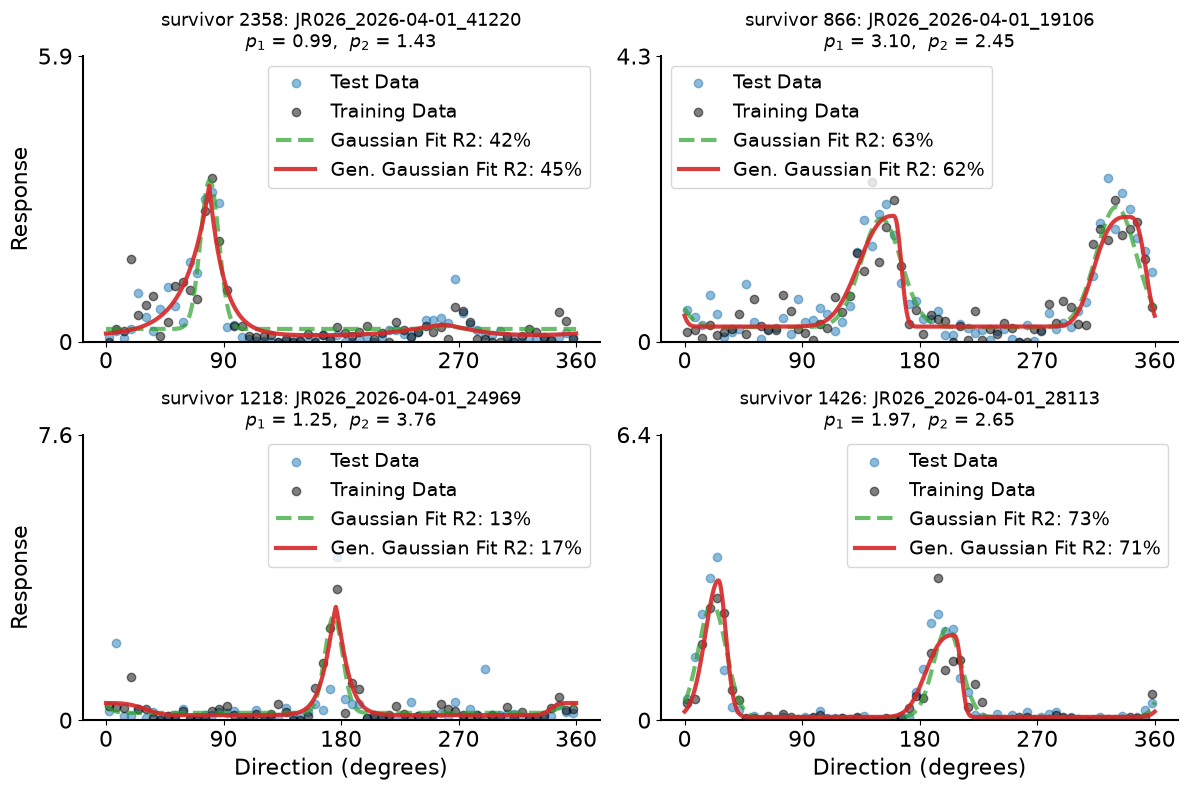

In [35]:
N_BINS_PLOT = 64   # test data is averaged down to this many points for display

def plot_examples(cells=None):
    if cells is None:
        cells = np.random.choice(len(R_test), 4, replace=False)
    theta = np.linspace(0, 2 * np.pi, 721)
    per = max(len(angles) // N_BINS_PLOT, 1)
    used = per * (len(angles) // per)
    chunk = lambda x: np.nanmean(x[..., :used].reshape(*x.shape[:-1], -1, per), -1)
    gauss_curves = predict('Gaussian', theta, params['Gaussian'][cells])
    gen_curves = predict('Gen. Gaussian', theta, params['Gen. Gaussian'][cells])
    exponents = params['Gen. Gaussian'][cells][:, [8, 9]].clamp(P_MIN, P_MAX).cpu().numpy()

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for i, (ax, c) in enumerate(zip(axes.flat, cells)):
        test = chunk(R_test[c])
        train = chunk(R_train[c])
        ax.scatter(chunk(angles), test, color='tab:blue', label='Test Data', alpha=0.5)
        ax.scatter(chunk(angles), train, color='black', label='Training Data', alpha=0.5)
        ax.plot(theta, gauss_curves[i], color='tab:green', linewidth=3, alpha=0.7, linestyle='--',
                label=f"Gaussian Fit R2: {100 * r2['Gaussian'][c]:.0f}%")
        ax.plot(theta, gen_curves[i], color='tab:red', linewidth=3, alpha=0.9,
                label=f"Gen. Gaussian Fit R2: {100 * r2['Gen. Gaussian'][c]:.0f}%")
        ax.set_title(f"survivor {c}: {survivor_names[c]}\n$p_1$ = {exponents[i, 0]:.2f},  $p_2$ = {exponents[i, 1]:.2f}", fontsize=13)
        ax.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
        ax.set_xticklabels(['0', '90', '180', '270', '360'], fontsize=16)
        top = 1.75 * max(np.nanmax(test), np.nanmax(train), gen_curves[i].max())
        #top = 1.75 * max(np.nanmax(test), gen_curves[i].max())
        ax.set_ylim(min(0.0, np.nanmin(test), np.nanmin(train)), top)
        #ax.set_ylim(min(0.0, np.nanmin(test)), top)
        ax.set_yticks([0, top])
        ax.set_yticklabels(['0', f'{top:.2g}'], fontsize=16)
        if i % 2 == 0:
            ax.set_ylabel('Response', fontsize=16)
        if i >= 2:
            ax.set_xlabel('Direction (degrees)', fontsize=16)
        ax.spines[['top', 'right']].set_visible(False)
        ax.spines[['bottom', 'left']].set_linewidth(1.5)
        ax.legend(fontsize=14, frameon=True)
    plt.tight_layout()
    plt.show()


plot_examples()

## Test R²: Gaussian vs generalised Gaussian

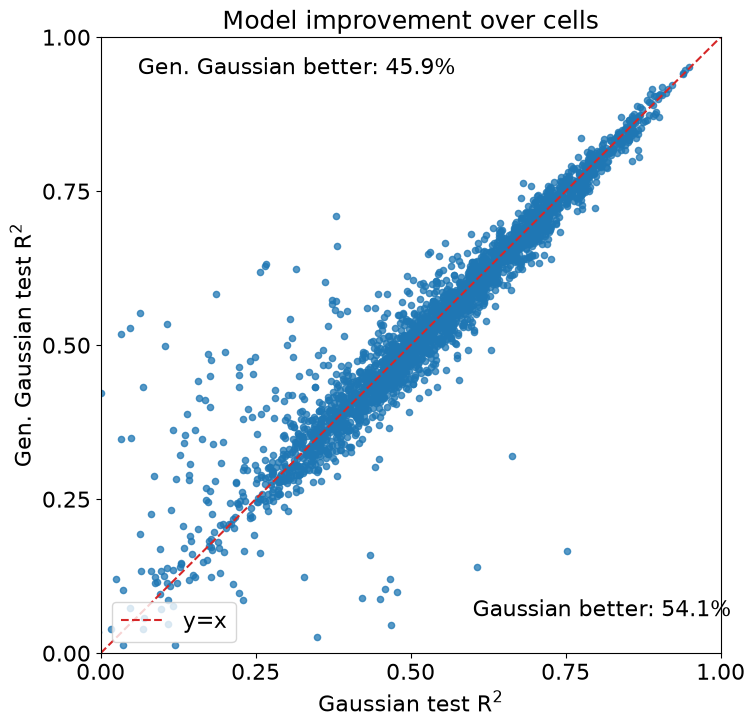

median ΔR² = -0.002, Wilcoxon p = 1.8e-04 (n = 3077 cells); 21 R² values below the plotted range


In [36]:
g, a = r2['Gaussian'], r2['Gen. Gaussian']
lo = min(0.6, np.floor(10 * np.percentile(np.r_[g, a], 1)) / 10)
ticks = np.round(np.linspace(lo, 1, 5), 2)
span = 1 - lo

plt.figure(figsize=(8, 8))
plt.scatter(g, a, color='tab:blue', alpha=0.75, s=20)
plt.plot([lo, 1], [lo, 1], color='tab:red', linestyle='--', label='y=x')
plt.xlim(lo, 1)
plt.ylim(lo, 1)
plt.xticks(ticks, fontsize=16)
plt.yticks(ticks, fontsize=16)
plt.xlabel('Gaussian test R$^2$', fontsize=16)
plt.ylabel('Gen. Gaussian test R$^2$', fontsize=16)
plt.text(lo + 0.06 * span, 1 - 0.06 * span, f'Gen. Gaussian better: {100 * np.mean(a > g):.1f}%', fontsize=16)
plt.text(lo + 0.6 * span, lo + 0.06 * span, f'Gaussian better: {100 * np.mean(g > a):.1f}%', fontsize=16)
plt.legend(fontsize=16, loc='lower left')
plt.title('Model improvement over cells', fontsize=18)
plt.show()

print(f'median ΔR² = {np.median(a - g):.3f}, Wilcoxon p = {wilcoxon(a, g).pvalue:.1e} (n = {len(g)} cells); '
      f'{(np.r_[g, a] < lo).sum()} R² values below the plotted range')

## Peakiness: min($p_1$, $p_2$)

This histogram uses only double-peaked cells with reproducible exponents. The generalised Gaussian is fitted a second time, on the odd repeats, so each cell has one fit per half of the data. The R² results above are unchanged.

A cell is kept if both of these hold:

1. **Both peaks are real in both fits:** the weaker peak's amplitude is at least `MIN_AMP_RATIO` times the stronger one's.
2. **Exponents agree:** $p_1$ and $p_2$ each differ by at most `P_REPRO_TOL` between the two fits.

The stronger peak can be labelled peak 1 in one fit and peak 2 in the other, so peaks are paired by their centres first. Each cell's value is the smaller of its two exponents, averaged across the two fits.

  Penalised fit: {'converged': 2981, 'deadline': 96}; 0 kept their starting estimate


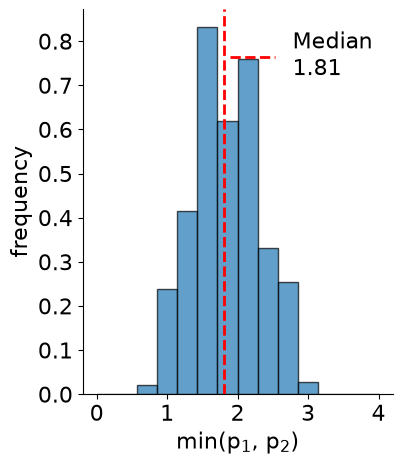

2570 of 3077 cells are double-peaked in both fits; 497 have p1 and p2 within 0.5 across fits; median 1.81


In [37]:
MIN_AMP_RATIO, P_REPRO_TOL = 0.1, 0.5

params_odd = fit('Gen. Gaussian', angles, R_test)


def peaks(P):
    # centre of peak 1, then (n_cells, 2) amplitudes and exponents, clipped as the model clips them
    P = P.cpu().numpy()
    return P[:, 0], P[:, 2:4].clip(min=0), P[:, 8:10].clip(P_MIN, P_MAX)


t_even, A_even, p_even = peaks(params['Gen. Gaussian'])
t_odd, A_odd, p_odd = peaks(params_odd)

# pair the peaks: swap the odd fit's labels where its peak 1 lies nearer the even fit's peak 2
swap = (np.abs(np.arctan2(np.sin(t_even - t_odd), np.cos(t_even - t_odd))) > np.pi / 2)[:, None]
A_odd, p_odd = np.where(swap, A_odd[:, ::-1], A_odd), np.where(swap, p_odd[:, ::-1], p_odd)

double = lambda A: A.min(1) / np.maximum(A.max(1), 1e-12) >= MIN_AMP_RATIO
is_double = double(A_even) & double(A_odd)
reproducible = is_double & (np.abs(p_even - p_odd) <= P_REPRO_TOL).all(1)
min_p = ((p_even + p_odd) / 2).min(1)[reproducible]

bins = np.linspace(0, P_MAX, 15)
plt.figure(figsize=(4, 5))
plt.hist(min_p, bins=bins, color='tab:blue', edgecolor='black', alpha=0.7, density=True)
plt.axvline(np.median(min_p), color='red', linestyle='--', linewidth=2, label=f'Median\n{np.median(min_p):.2f}')
plt.xticks(np.arange(0, P_MAX + 1), fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel('min(p$_1$, p$_2$)', fontsize=16)
plt.ylabel('frequency', fontsize=16)
plt.legend(fontsize=16, frameon=False)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

print(f'{is_double.sum()} of {len(is_double)} cells are double-peaked in both fits; '
      f'{reproducible.sum()} have p1 and p2 within {P_REPRO_TOL} across fits; median {np.median(min_p):.2f}')

In [38]:
import csv

GAUSS_COLS = ['theta_pref', 'baseline', 'amp_1', 'amp_2', 'width']
GG_COLS = ['theta_pref', 'baseline', 'amp_1', 'amp_2', 'width_left_1', 'width_right_1',
           'width_left_2', 'width_right_2', 'p_1', 'p_2']


def clamped(P, model):
    # the same limits the model applies when it draws a curve (see gauss / gen_gauss)
    P = P.detach().cpu().numpy().astype(float).copy()
    P[:, 0] = P[:, 0].clip(0, 2 * np.pi)
    P[:, 1:4] = P[:, 1:4].clip(min=0)
    if model == 'Gaussian':
        P[:, 4] = P[:, 4].clip(min=0.01)
    else:
        P[:, 4:8] = P[:, 4:8].clip(MIN_WIDTH, MAX_WIDTH)
        P[:, 8:10] = P[:, 8:10].clip(P_MIN, P_MAX)
    return P


gauss_P = clamped(params['Gaussian'], 'Gaussian')                 # fitted on the even repeats
gg_even_P = clamped(params['Gen. Gaussian'], 'Gen. Gaussian')     # fitted on the even repeats
gg_odd_P = clamped(params_odd, 'Gen. Gaussian')                   # fitted on the odd repeats; peak labels left as the fit returned them

# min(p1, p2) averaged over the two Gen. Gaussian fits (odd peaks paired to the even ones), reproducible cells only
min_p_col = np.where(reproducible, ((p_even + p_odd) / 2).min(1), np.nan)

header = (['cell_name']
          + [f'gauss_{c}' for c in GAUSS_COLS]
          + [f'gg_even_{c}' for c in GG_COLS]
          + [f'gg_odd_{c}' for c in GG_COLS]
          + ['gg_odd_swapped', 'reproducible', 'min_p'])

fits_path = f"JR026/{stem}_will_fits.csv"
assert len(survivor_names) == len(gauss_P) == len(gg_even_P) == len(gg_odd_P) == len(min_p_col)
with open(fits_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(header)
    for k, name in enumerate(survivor_names):
        w.writerow([name, *gauss_P[k], *gg_even_P[k], *gg_odd_P[k],
                    int(swap[k, 0]), int(reproducible[k]),
                    '' if np.isnan(min_p_col[k]) else min_p_col[k]])
print(f"saved {fits_path}: {len(survivor_names)} cells, {reproducible.sum()} reproducible")


saved JR026/JR026_2026-04-01_will_fits.csv: 3077 cells, 497 reproducible
